# Import Libraries

In [1]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, MultiLabelBinarizer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

import warnings
warnings.filterwarnings("ignore")

# Load Dataset

In [2]:
df=pd.read_csv(r"C:\Users\ADMIN\OneDrive\Desktop\Auspify_ML_Internship\Data\Dataset.csv")
print("Dataset Shape:",df.shape)
df.head()

Dataset Shape: (8790, 10)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [3]:
# 1. Extract numeric duration and encode content type as binary (Movie=0, TV Show=1)
df["duration_num"] = df["duration"].str.extract(r"(\d+)").astype(float)
df["is_tv_show"] = (df["type"] == "TV Show").astype(int)

# 2. Multi-label encode genres ('listed_in')
genres_list = [[g.strip() for g in item.split(",")] for item in df["listed_in"]]
mlb = MultiLabelBinarizer()
genre_encoded = mlb.fit_transform(genres_list)
genre_df = pd.DataFrame(genre_encoded, columns=mlb.classes_, index=df.index)

# 3. Combine numerical and genre features, then standardize for K-Means
X_cluster = pd.concat([df[["release_year", "duration_num", "is_tv_show"]], genre_df], axis=1)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

print("Feature matrix shape:", X_cluster.shape)
print("Missing values:", X_cluster.isnull().sum().sum())

Feature matrix shape: (8790, 45)
Missing values: 0


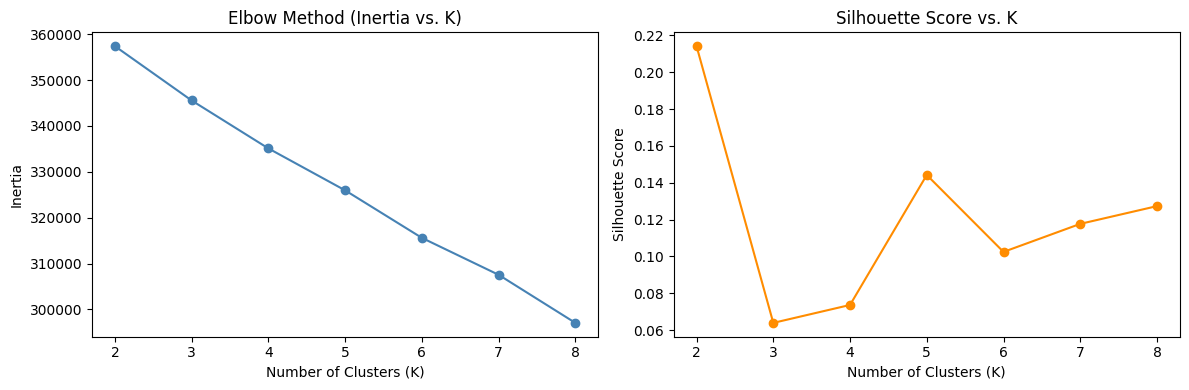

K=2 | Inertia: 357,386 | Silhouette Score: 0.2142
K=3 | Inertia: 345,541 | Silhouette Score: 0.0639
K=4 | Inertia: 335,091 | Silhouette Score: 0.0736
K=5 | Inertia: 325,948 | Silhouette Score: 0.1442
K=6 | Inertia: 315,589 | Silhouette Score: 0.1024
K=7 | Inertia: 307,535 | Silhouette Score: 0.1177
K=8 | Inertia: 297,053 | Silhouette Score: 0.1273


In [4]:
inertias = []
sil_scores = []
k_values = range(2, 9)

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels, sample_size=3000, random_state=42))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(k_values, inertias, marker="o", color="steelblue")
ax[0].set_title("Elbow Method (Inertia vs. K)")
ax[0].set_xlabel("Number of Clusters (K)")
ax[0].set_ylabel("Inertia")

ax[1].plot(k_values, sil_scores, marker="o", color="darkorange")
ax[1].set_title("Silhouette Score vs. K")
ax[1].set_xlabel("Number of Clusters (K)")
ax[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

for k, iner, sil in zip(k_values, inertias, sil_scores):
    print(f"K={k} | Inertia: {iner:,.0f} | Silhouette Score: {sil:.4f}")

In [5]:
optimal_k = 5
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df["cluster"] = kmeans.fit_predict(X_scaled)

print("Titles per cluster:\n", df["cluster"].value_counts().sort_index())

Titles per cluster:
 cluster
0     849
1    5317
2     825
3    1180
4     619
Name: count, dtype: int64


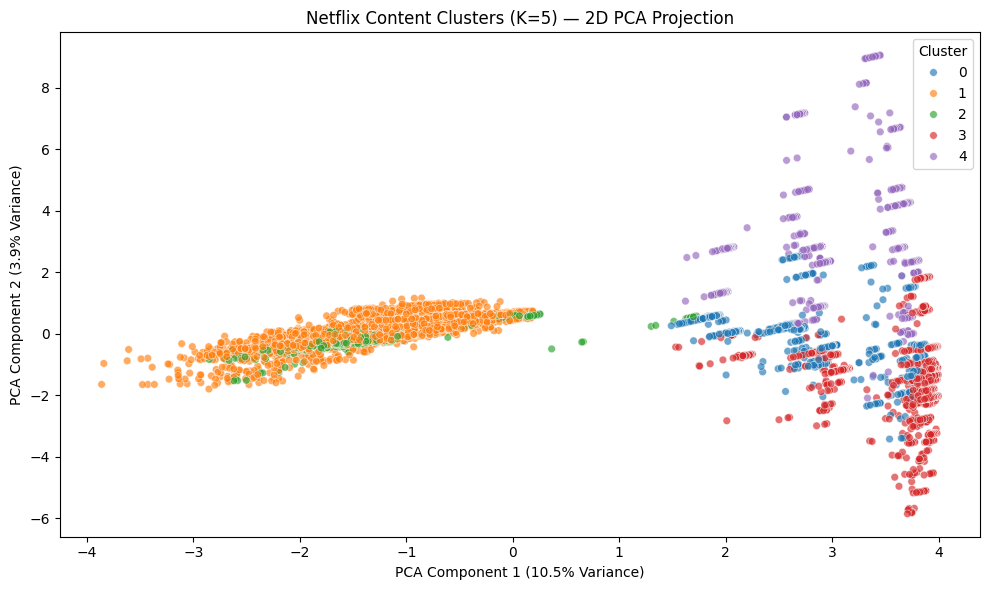

In [6]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

df["pca_1"] = X_pca[:, 0]
df["pca_2"] = X_pca[:, 1]

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x="pca_1",
    y="pca_2",
    hue="cluster",
    palette="tab10",
    alpha=0.65,
    s=30
)
plt.title(f"Netflix Content Clusters (K={optimal_k}) — 2D PCA Projection")
plt.xlabel(f"PCA Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}% Variance)")
plt.ylabel(f"PCA Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}% Variance)")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

In [7]:
for c in range(optimal_k):
    sub = df[df["cluster"] == c]
    top_type = sub["type"].mode()[0]
    avg_year = sub["release_year"].mean()
    avg_dur = sub["duration_num"].mean()
    top_genre = sub["listed_in"].value_counts().index[0]
    unit = "Seasons" if top_type == "TV Show" else "min"
    print(f"Cluster {c} ({len(sub)} titles) -> Dominant: {top_type} | Avg Year: {avg_year:.1f} | Avg Duration: {avg_dur:.1f} {unit} | Top Genre: {top_genre}")

# Save clustering artifacts
joblib.dump(
    {"kmeans": kmeans, "scaler": scaler, "mlb": mlb, "features": X_cluster.columns.tolist()},
    "segmentation_artifacts.pkl"
)
print("\nSaved segmentation_artifacts.pkl successfully!")

Cluster 0 (849 titles) -> Dominant: TV Show | Avg Year: 2016.2 | Avg Duration: 2.1 Seasons | Top Genre: Kids' TV
Cluster 1 (5317 titles) -> Dominant: Movie | Avg Year: 2012.9 | Avg Duration: 99.9 min | Top Genre: Dramas, International Movies
Cluster 2 (825 titles) -> Dominant: Movie | Avg Year: 2014.1 | Avg Duration: 95.6 min | Top Genre: Dramas, Independent Movies, International Movies
Cluster 3 (1180 titles) -> Dominant: TV Show | Avg Year: 2016.7 | Avg Duration: 1.7 Seasons | Top Genre: International TV Shows, TV Dramas
Cluster 4 (619 titles) -> Dominant: TV Show | Avg Year: 2017.5 | Avg Duration: 1.4 Seasons | Top Genre: Reality TV

Saved segmentation_artifacts.pkl successfully!
